# JS08: Tugas Lab 1

Klasterisasi data nasabah kartu kredit dengan Agglomerative Clustering.


## Persiapan dataset


In [1]:
from pathlib import Path
from urllib.request import Request, urlopen
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score, davies_bouldin_score
import scipy.cluster.hierarchy as sch

data_path = Path('CC_Customer_Dataset.csv')
if not data_path.exists():
    url = 'https://1812311909-files.gitbook.io/~/files/v0/b/gitbook-x-prod.appspot.com/o/spaces%2FYHOv2XH8FJMJSMsnhwNa%2Fuploads%2FtUHTofsaCAu01AQLD2W1%2FCC_Customer_Dataset.csv?alt=media&token=f41e58d9-7c29-4e26-8e16-f93bf44c0556'
    req = Request(url, headers={'User-Agent': 'Mozilla/5.0'})
    with urlopen(req, timeout=120) as resp:
        data_path.write_bytes(resp.read())

df = pd.read_csv(data_path)
print('Ukuran data:', df.shape)
print('Jumlah nilai kosong:', df.isna().sum().sum())
df.head()


Ukuran data: (660, 7)
Jumlah nilai kosong: 0


## Soal 1: Model Agglomerative Clustering seluruh variabel

Model menggunakan seluruh lima fitur: Avg_Credit_Limit, Total_Credit_Cards, Total_visits_bank, Total_visits_online, dan Total_calls_made. Kolom Sl_No serta Customer Key dikeluarkan karena merupakan identitas nasabah. Standardisasi menyetarakan skala limit kredit dengan jumlah kartu dan aktivitas nasabah.


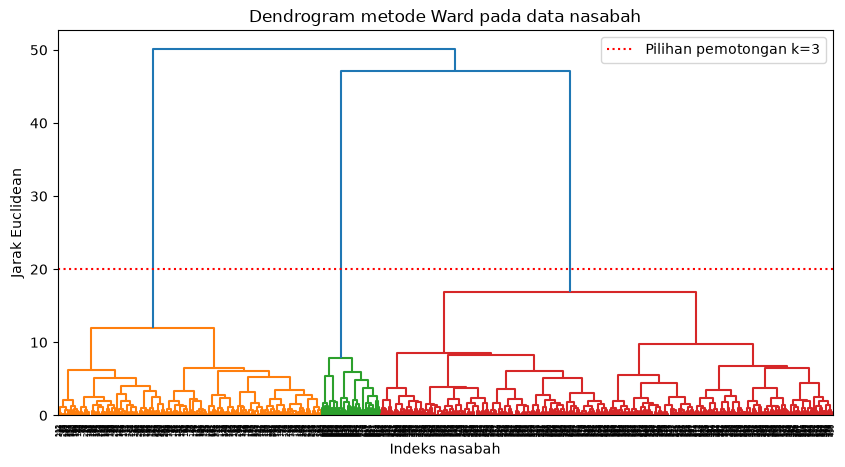

In [2]:
features = df.drop(columns=['Sl_No', 'Customer Key'])
scaler = StandardScaler()
X = scaler.fit_transform(features)

plt.figure(figsize=(10, 5))
dendrogram = sch.dendrogram(sch.linkage(X, method='ward'))
plt.title('Dendrogram metode Ward pada data nasabah')
plt.xlabel('Indeks nasabah')
plt.ylabel('Jarak Euclidean')
plt.axhline(20, color='red', linestyle=':', label='Pilihan pemotongan k=3')
plt.legend()
plt.show()


In [3]:
K = range(2, 7)
sil_scores = []
dbi_scores = []

for k in K:
    model = AgglomerativeClustering(n_clusters=k, metric='euclidean', linkage='ward')
    labels = model.fit_predict(X)
    sil_scores.append(silhouette_score(X, labels))
    dbi_scores.append(davies_bouldin_score(X, labels))

eval_df = pd.DataFrame({'k': list(K), 'Silhouette': sil_scores, 'DBI': dbi_scores})
print(eval_df.to_string(index=False, float_format=lambda v: f'{v:.4f}'))


 k  Silhouette    DBI
 2      0.4177 0.9326
 3      0.5148 0.6810
 4      0.3481 1.1493
 5      0.2569 1.3851
 6      0.2268 1.4109


Saya memilih k=3. Silhouette score mencapai nilai tertinggi pada k=3 sebesar 0,5148 dan DBI mencapai nilai terendah sebesar 0,6810. Penurunan silhouette yang tajam pada k=4 (menjadi 0,3947) memperkuat pemilihan tiga klaster.


In [4]:
best_k = 3
hc = AgglomerativeClustering(n_clusters=best_k, metric='euclidean', linkage='ward')
hc_labels = hc.fit_predict(X)
df['Cluster'] = hc_labels

print('Jumlah anggota tiap klaster:')
print(pd.Series(hc_labels).value_counts().sort_index())


Jumlah anggota tiap klaster:
0    385
1    225
2     50
Name: count, dtype: int64


## Soal 2: Scatterplot dua variabel (Avg_Credit_Limit dan Total_credit_card)

Kolom yang disebut Total_credit_card dalam soal bernama Total_Credit_Cards pada dataset. Warna berasal dari model lima fitur. Scatterplot menampilkan proyeksinya pada dua variabel yang diminta.


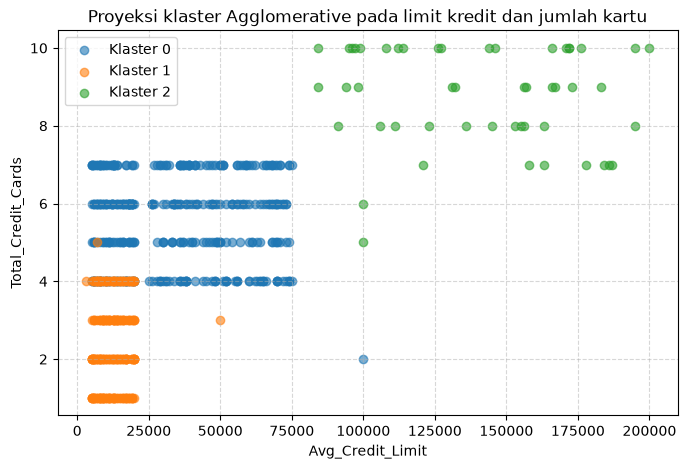

In [5]:
plt.figure(figsize=(8, 5))
for label in sorted(np.unique(hc_labels)):
    mask = hc_labels == label
    plt.scatter(df.loc[mask, 'Avg_Credit_Limit'], df.loc[mask, 'Total_Credit_Cards'],
                alpha=0.6, label=f'Klaster {label}')

plt.xlabel('Avg_Credit_Limit')
plt.ylabel('Total_Credit_Cards')
plt.title('Proyeksi klaster Agglomerative pada limit kredit dan jumlah kartu')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()


Bentuk klaster terpisah dengan pola yang teratur: klaster 1 terkonsentrasi pada limit kredit rendah di bawah 20.000 dengan 1–4 kartu; klaster 0 berada pada limit menengah 30.000–40.000 dengan 4–6 kartu; dan klaster 2 berada pada limit tinggi di atas 80.000 dengan 5–10 kartu.


## Soal 3: Silhouette score dan DBI

Evaluasi kuantitatif pemisahan klaster model Agglomerative pada data standar.


In [6]:
final_sil = silhouette_score(X, hc_labels)
final_dbi = davies_bouldin_score(X, hc_labels)

metric_summary = pd.DataFrame([{
    'Model': 'Agglomerative (k=3)',
    'Jumlah data': len(X),
    'Silhouette': final_sil,
    'DBI': final_dbi
}])
print(metric_summary.to_string(index=False, float_format=lambda v: f'{v:.6f}'))

print('\nRata-rata fitur per klaster:')
profile = df.groupby('Cluster')[features.columns].mean()
print(profile.to_string(float_format=lambda v: f'{v:.2f}'))


              Model  Jumlah data  Silhouette      DBI
Agglomerative (k=3)          660    0.514764 0.680960
Rata-rata fitur per klaster:
         Avg_Credit_Limit  Total_Credit_Cards  Total_visits_bank  Total_visits_online  Total_calls_made
Cluster                                                                                                
0                33851.95                5.52               3.49                 0.98              1.99
1                12151.11                2.42               0.94                 3.55              6.86
2               141040.00                8.74               0.60                10.90              1.08


## Analisis hasil

Agglomerative Clustering dengan linkage Ward membentuk tiga klaster yang stabil pada lima fitur nasabah. Klaster 0 merupakan nasabah reguler dengan kunjungan bank fisik aktif. Klaster 1 adalah nasabah entry-level dengan interaksi call center tertinggi. Klaster 2 adalah nasabah premium dengan limit tinggi dan transaksi online dominan. Nilai silhouette score sebesar 0,5148 dan DBI 0,6810 sejalan dengan struktur tiga klaster K Means pada JS07, menegaskan bahwa partisi tiga kelompok ini merupakan struktur alami data nasabah.
